In [1]:
import matplotlib.pyplot as plt 
import torch
from tqdm import tqdm

from model import ExponentialRepresentation

from scipy.stats import binned_statistic_2d

In [13]:
# def block_diag(n):
#     a = 2*torch.rand(n-1) - 1 # [-1, 1]
#     u = torch.diag(a, 1) 
#     return u - u.T

def block_diag(n):
    blocks = []
    for i in range(n):
        block = torch.zeros((2,2))
        block[0,1] =  2*torch.rand(1)[0] - 1
        block[1,0] = -block[0,1]
        blocks.append(block)
    return torch.block_diag(*blocks)

def plot_ratemaps(x, y, f, n = 5, bins = 32, figsize = (2,2)):
    fig, ax = plt.subplots(n, n, figsize = figsize)
    axs = ax.ravel()
    hists = binned_statistic_2d(x,y, f.T, bins = bins)[0]

    for i in range(n**2):
        axs[i].imshow(hists[i])
        axs[i].axis("off")

In [3]:
n_units = 100

In [4]:
A = block_diag(n_units//2)
B = block_diag(n_units//2)

model = ExponentialRepresentation(A, B)

tensor(0.)


In [5]:
f0 = torch.rand(n_units)

In [23]:
ns = 10_000
r = 10*torch.rand((ns, 2))
v = torch.diff(r, dim = 0)

In [24]:
f = model(v, f0)

100%|██████████| 9998/9998 [00:04<00:00, 2094.07it/s]


In [25]:
f.shape, r.shape

(torch.Size([9999, 100]), torch.Size([10000, 2]))

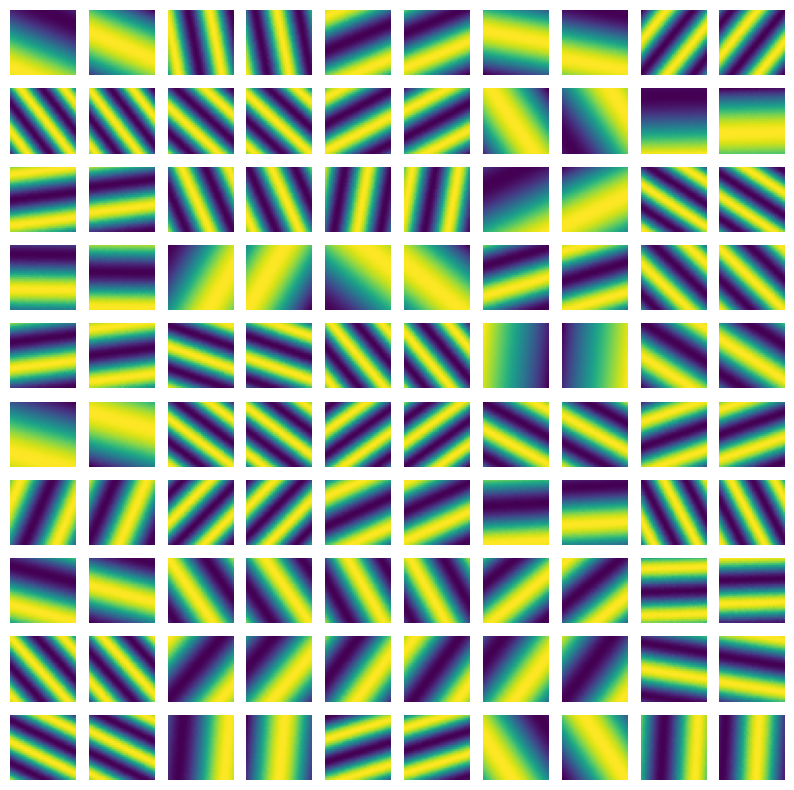

In [26]:
plot_ratemaps(r[:-1,0], r[:-1,1], f, 10, figsize=(10,10))